# Solution: Mission — Release-Ready Toolkit

One possible solution with the topics of M02 (uv, Ruff, pytest, clean code) and M03 (Git). Every command runs for real in a temporary folder.

In [1]:
import random
import shutil
import subprocess
import tempfile
import timeit
from pathlib import Path

random.seed(0)
weekly_events = [{"day": random.choice(["Mon", "Tue", "Wed", "Thu", "Fri"]), "tickets": random.randint(0, 80),
                  "severity": random.choice(["low", "medium", "high"])} for _ in range(200_000)]

def build_report_slow(items):
    report = []
    for item in items:
        if item["tickets"] >= 30:
            report.append(f"{item['day']}: {item['tickets']} tickets")
    return report

def build_report_fast(items):
    return [f"{d}: {t} tickets" for d, t in ((i["day"], i["tickets"]) for i in items) if t >= 30]

assert build_report_slow(weekly_events) == build_report_fast(weekly_events)

## 1. Profile first, then optimise

Measure both versions on a realistic data size (200,000 events, synthetic). Five events, as in the mission text, are too few to measure anything.

slow 24.7 ms | fast 29.6 ms | ratio 0.83


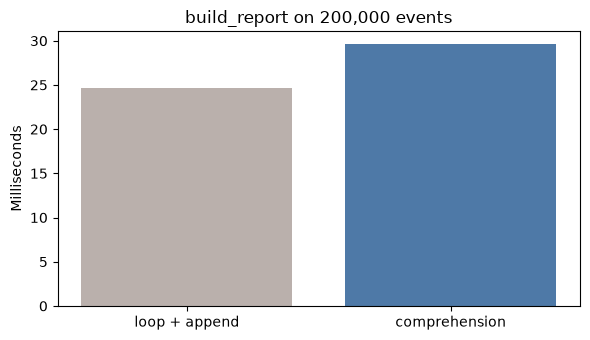

In [2]:
import matplotlib.pyplot as plt

slow = min(timeit.repeat(lambda: build_report_slow(weekly_events), number=3, repeat=3)) / 3
fast = min(timeit.repeat(lambda: build_report_fast(weekly_events), number=3, repeat=3)) / 3
print(f"slow {slow * 1000:.1f} ms | fast {fast * 1000:.1f} ms | ratio {slow / fast:.2f}")

fig, ax = plt.subplots(figsize=(6, 3.5))
ax.bar(["loop + append", "comprehension"], [slow * 1000, fast * 1000], color=["#BAB0AC", "#4E79A7"])
ax.set(title="build_report on 200,000 events", ylabel="Milliseconds")
plt.tight_layout()
plt.show()

The ratio is close to 1: the "fast" version is not meaningfully faster. (On the reference machine it was even slightly slower, because it creates an extra tuple for every item.) In Python 3.12 a comprehension is not much faster than a simple loop (M01 Lesson 05). The honest conclusion for the team: the report builder is **not** the bottleneck. Keep the version that is easier to read, and profile the whole tool (M01 Lesson 17) before optimising further.

## 2. A reproducible project with uv and Git

In [3]:
uv, git = shutil.which("uv"), shutil.which("git")
work = Path(tempfile.mkdtemp())

def sh(cmd, cwd):
    r = subprocess.run(cmd, cwd=cwd, capture_output=True, text=True)
    shown = [Path(cmd[0]).name] + [c.replace(str(work), "<tmp>") for c in cmd[1:]]
    print(f"$ {' '.join(shown)}\n{(r.stdout + r.stderr).strip().replace(str(work), '<tmp>')}\n")

proj = work / "ticket-report"
sh([uv, "init", "--lib", "--name", "ticket-report", "--python", "3.12", str(proj)], work)
(proj / "src" / "ticket_report" / "__init__.py").write_text(
    "def build_report(items, threshold=30):\n"
    "    return [f\"{i['day']}: {i['tickets']} tickets\" for i in items if i['tickets'] >= threshold]\n")
(proj / "tests").mkdir()
(proj / "tests" / "test_report.py").write_text(
    "from ticket_report import build_report\n\n"
    "def test_threshold():\n"
    "    assert build_report([{'day': 'Mon', 'tickets': 31}, {'day': 'Tue', 'tickets': 5}]) == ['Mon: 31 tickets']\n")
sh([uv, "add", "--dev", "pytest", "ruff"], proj)
sh([uv, "run", "ruff", "check", "."], proj)
sh([uv, "run", "pytest", "-q", "-p", "no:cacheprovider"], proj)

$ uv init --lib --name ticket-report --python 3.12 <tmp>/ticket-report
Initialized project `ticket-report` at `<tmp>/ticket-report`



$ uv add --dev pytest ruff
Using CPython 3.12.16
Creating virtual environment at: .venv
Resolved 8 packages in 242ms
   Building ticket-report @ file://<tmp>/ticket-report
      Built ticket-report @ file://<tmp>/ticket-report
Prepared 1 package in 5ms
Installed 7 packages in 9ms
 + iniconfig==2.3.1
 + packaging==26.3
 + pluggy==1.7.0
 + pygments==2.21.0
 + pytest==9.2.0
 + ruff==0.17.5
 + ticket-report==0.1.0 (from file://<tmp>/ticket-report)

$ uv run ruff check .
I001 [*] Import block is un-sorted or un-formatted
 --> tests/test_report.py:1:1
  |
1 | from ticket_report import build_report
  | ^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
2 |
3 | def test_threshold():
  |
help: Organize imports
  |
2 |
3 +
4 | def test_threshold():
  |

Found 1 error.
[*] 1 fixable with `--fix`.



$ uv run pytest -q -p no:cacheprovider
.                                                                        [100%]
1 passed in 0.01s



In [4]:
env = {"GIT_AUTHOR_NAME": "Course Student", "GIT_AUTHOR_EMAIL": "student@example.com",
       "GIT_COMMITTER_NAME": "Course Student", "GIT_COMMITTER_EMAIL": "student@example.com"}
import os
os.environ.update(env)
# `uv init` already created a Git repository with a .gitignore, so we only commit.
sh([git, "add", "."], proj)
sh([git, "commit", "-q", "-m", "add ticket report library with tests"], proj)
sh([git, "switch", "-c", "feature/configurable-threshold"], proj)
(proj / "README.md").write_text("# ticket-report\n\nRun the tests: `uv sync && uv run pytest`\n")
sh([git, "add", "README.md"], proj)
sh([git, "commit", "-q", "-m", "document how to run the tests"], proj)
sh([git, "log", "--oneline", "--all", "--graph"], proj)

$ git add .


$ git commit -q -m add ticket report library with tests


$ git switch -c feature/configurable-threshold
Switched to a new branch 'feature/configurable-threshold'

$ git add README.md


$ git commit -q -m document how to run the tests


$ git log --oneline --all --graph
* a5dbd02 document how to run the tests
* e298653 add ticket report library with tests



## Hand-off checklist

- `pyproject.toml` and `uv.lock` define the environment; `uv sync` recreates it.
- Ruff reports no problems; pytest passes.
- Work happens on a feature branch with small, clearly named commits, ready for a pull request (M03).
- The benchmark shows the optimisation result honestly, including when it is small.